<img src="https://raw.githubusercontent.com/telmomm/CERTA/main/docs/assets/logo/certa-logo.png" alt="CERTA" width="220">

# T0.3 · Full-text screening and PRISMA

*The records that pass title and abstract, their full-text decisions and the PRISMA 2020 flow*

Takes the records that pass the title and abstract screening (`include` or `doubt` in `screening.csv`), prepares the sheet for the full-text decision, and computes the numbers and the diagram of the PRISMA 2020 flow.

- **Input:** `screening.csv`; `../T0.2-search-and-deduplication/corpus.csv` and `counts.csv`; the PDFs in `../T0.5-data-extraction/pdf/`.
- **Output:** `full_text.csv` (one row per record to read in full, with `decision`, `reason` and `notes` filled in by hand), `prisma.csv` and `prisma.png`.
- **To re-run:** run all cells. The full-text decisions already written in `full_text.csv` are kept; records that enter or leave the list after a change in `screening.csv` are added or reported.
- **Environment:** the repository `.venv` (see `CONTRIBUTING.md`).

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

pd.set_option("display.max_colwidth", 90)
CERTA = {"navy": "#0B2D4A", "teal": "#00BFA5", "blue": "#00AEEF", "sky": "#A7E3F7", "ice": "#E6EEF6"}

class table:
    """Shows a DataFrame with the CERTA colours in the notebook and as a LaTeX table in the PDF export.
    `bar` is a numeric column drawn as bars."""
    def __init__(self, df, bar=None):
        self.df, self.bar = df, bar
    def _repr_html_(self):
        styler = self.df.style.hide(axis="index").set_table_styles([
            {"selector": "th", "props": f"background-color: {CERTA['navy']}; color: white; text-align: left;"},
            {"selector": "tbody tr:nth-child(even)", "props": f"background-color: {CERTA['ice']};"},
        ])
        if self.bar is not None:
            styler = styler.bar(subset=[self.bar], color=CERTA["teal"], vmin=0)
        return styler.to_html()
    def _repr_latex_(self):
        return self.df.style.hide(axis="index").format(precision=3).to_latex(hrules=True)
    def __repr__(self):
        return self.df.to_string(index=False)

T02 = Path("../T0.2-search-and-deduplication")
CORPUS, COUNTS = T02 / "corpus.csv", T02 / "counts.csv"
SCREENING = Path("screening.csv")
PDF = Path("../T0.5-data-extraction/pdf")       # full texts, named <id>.pdf; the folder is not committed
FULL_TEXT = Path("full_text.csv")
PRISMA, FIGURE = Path("prisma.csv"), Path("prisma.png")

DECISIONS = ["include", "exclude"]
REASONS = {
    "E1": "digital only", "E2": "diagnosis without selection", "E3": "other domain",
    "E4": "test technique or structure without selection or coverage", "E5": "not a primary study",
    "E6": "redundant version", "E7": "language", "E8": "full text not available",
}

## 1. Records to read in full

Every record with `include` or `doubt` at title and abstract. A doubt is read in full like an inclusion. The sheet says where each record comes from (block S1, S2 or tracking), whether its PDF is already in `T0.5-data-extraction/pdf/`, and leaves three columns for the decision:

| Column | Values |
| --- | --- |
| `decision` | `include` or `exclude` |
| `reason` | Only if `exclude`: E1 to E8, the same reasons as at title and abstract plus E6 (redundant version: the most complete one is kept) and E8 (full text not available) |
| `notes` | Free text; for E6, the identifier of the version that is kept |

In [2]:
corpus = pd.read_csv(CORPUS, dtype=str).fillna("").set_index("id")
screening = pd.read_csv(SCREENING, dtype=str).fillna("").set_index("id")
passed = screening.index[screening["decision"].isin(["include", "doubt"])]

sheet = pd.DataFrame(index=pd.Index(passed, name="id"))
sheet["blocks"] = corpus.loc[passed, "blocks"]
sheet["title_abstract"] = screening.loc[passed, "decision"]
sheet["year"] = corpus.loc[passed, "year"]
sheet["title"] = corpus.loc[passed, "title"]
sheet["doi"] = corpus.loc[passed, "doi"]
sheet["possible_version"] = corpus.loc[passed, "possible_version"]
sheet["pdf"] = ["y" if (PDF / f"{i}.pdf").exists() else "n" for i in passed]
for column in ["decision", "reason", "notes"]:
    sheet[column] = ""

# Keep the full-text decisions already written by hand
if FULL_TEXT.exists():
    old = pd.read_csv(FULL_TEXT, dtype=str).fillna("").set_index("id")
    kept = old.index.intersection(sheet.index)
    sheet.loc[kept, ["decision", "reason", "notes"]] = old.loc[kept, ["decision", "reason", "notes"]]
    left = old.index.difference(sheet.index)
    if len(left):
        print("No longer at full text (changed in screening.csv):", ", ".join(left))
        print("  their full-text decisions were:", old.loc[left, "decision"].replace("", "none").value_counts().to_dict())

sheet = sheet.sort_values(["pdf", "year", "title"], ascending=[False, False, True])
sheet.to_csv(FULL_TEXT, encoding="utf-8")
print("records to read in full:", len(sheet), "| with PDF:", (sheet["pdf"] == "y").sum())
table(pd.crosstab(sheet["blocks"], sheet["title_abstract"], margins=True, margins_name="total").reset_index())

records to read in full: 768 | with PDF: 38


blocks,doubt,include,total
S1,149,273,422
S1+S2,1,1,2
S1+S2+tracking,2,2,4
S1+tracking,47,160,207
S2,19,7,26
S2+tracking,1,0,1
tracking,74,32,106
total,293,475,768


## 2. Checking the full-text decisions

Invalid codes are listed so they can be corrected in `full_text.csv`. A record can be excluded by E8 only when its full text could not be obtained.

In [3]:
ft = pd.read_csv(FULL_TEXT, dtype=str).fillna("").set_index("id")
errors = ft[
    ~ft["decision"].isin(DECISIONS + [""])
    | ((ft["decision"] == "exclude") & ~ft["reason"].isin(REASONS))
    | ((ft["decision"] != "exclude") & (ft["reason"] != ""))
    | ((ft["reason"] == "E8") & (ft["pdf"] == "y"))
]
print("decided:", (ft["decision"] != "").sum(), "of", len(ft), "| invalid:", len(errors))
if len(errors):
    display(table(errors.reset_index()[["id", "pdf", "decision", "reason", "notes"]]))

decided: 0 of 768 | invalid: 0


## 3. PRISMA 2020 flow

The PRISMA 2020 diagram keeps apart the records identified in the databases (blocks S1 and S2) from those identified by other methods (the citation and author tracking of T0.4). A record found by both counts in the databases column. The full-text boxes stay pending until every record of `full_text.csv` has a decision.

In [4]:
counts = pd.read_csv(COUNTS).set_index("item")["records"]
blocks = corpus["blocks"]
from_db = blocks.str.contains("S1|S2")
column = pd.Series(["databases" if d else "other methods" for d in from_db], index=corpus.index)

ta = screening["decision"].reindex(corpus.index)
ft_dec = ft["decision"].reindex(corpus.index).fillna("")
ft_reason = ft["reason"].reindex(corpus.index).fillna("")

def by(col):
    mask = column == col
    passed_col = mask & ta.isin(["include", "doubt"])
    not_retrieved = passed_col & (ft_reason == "E8")
    assessed = passed_col & ~(ft_reason == "E8")
    return {
        "screened": int(mask.sum()),
        "excluded at title and abstract": int((mask & (ta == "exclude")).sum()),
        "sought for retrieval": int(passed_col.sum()),
        "not retrieved": int(not_retrieved.sum()),
        "assessed at full text": int(assessed.sum()),
        "pending at full text": int((assessed & (ft_dec == "")).sum()),
        "excluded at full text": int((assessed & (ft_dec == "exclude")).sum()),
        "included": int((assessed & (ft_dec == "include")).sum()),
    }

db_queries = [k for k in counts.index if k.startswith(("Scopus", "Web of Science", "IEEE Xplore"))]
tracking = [k for k in counts.index if k.startswith("Tracking")]
identified_db, identified_other = int(counts[db_queries].sum()), int(counts[tracking].sum())
removed = int(counts["Removed: duplicates"] + counts["Removed: no authors (front matter, proceedings, standards)"]
              + counts["Removed: document type (tracking)"])
prisma = pd.DataFrame({"databases": by("databases"), "other methods": by("other methods")})
prisma.loc["identified"] = [identified_db, identified_other]
prisma = prisma.loc[["identified"] + [i for i in prisma.index if i != "identified"]]
prisma.to_csv(PRISMA, index_label="stage", encoding="utf-8")
print("removed before screening (duplicates, front matter, document type):", removed)
table(prisma.reset_index().rename(columns={"index": "stage"}))

removed before screening (duplicates, front matter, document type): 1831


stage,databases,other methods
identified,3451,1114
screened,1987,747
excluded at title and abstract,1325,641
sought for retrieval,662,106
not retrieved,0,0
assessed at full text,662,106
pending at full text,662,106
excluded at full text,0,0
included,0,0


Exclusion reasons at title and abstract, by column of the diagram.

In [5]:
excluded = (ta == "exclude")
reasons = pd.crosstab(screening["reason"].reindex(corpus.index)[excluded], column[excluded])
reasons.index = [f"{r} · {REASONS.get(r, r)}" for r in reasons.index]
table(reasons.reset_index().rename(columns={"index": "reason"}))

reason,databases,other methods
E1 · digital only,144,13
E2 · diagnosis without selection,224,112
E3 · other domain,200,423
E4 · test technique or structure without selection or coverage,579,56
E5 · not a primary study,117,15
E7 · language,61,22


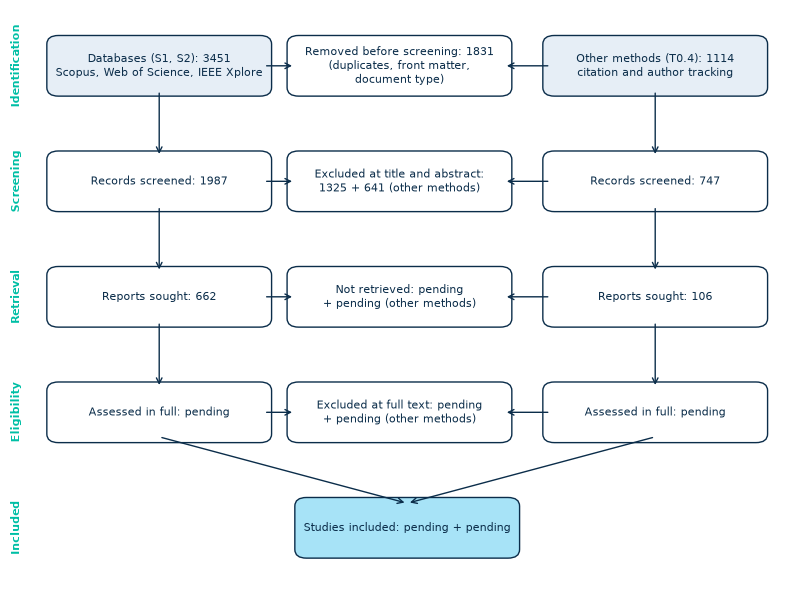

In [6]:
def box(ax, x, y, w, h, text, fill):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.01,rounding_size=0.015",
                                fc=fill, ec=CERTA["navy"], lw=1))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=8, color=CERTA["navy"], wrap=True)

def arrow(ax, x0, y0, x1, y1):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="->", color=CERTA["navy"], lw=1))

d, o = prisma["databases"], prisma["other methods"]
pending = d["pending at full text"] + o["pending at full text"]
ft_text = lambda col, key: "pending" if pending else f"{col[key]}"
fig, ax = plt.subplots(figsize=(10, 7.5))
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")
W, H = 0.27, 0.085
rows = [0.86, 0.66, 0.46, 0.26, 0.06]
L, R, X = 0.05, 0.36, 0.69
box(ax, L, rows[0], W, H, f"Databases (S1, S2): {identified_db}\nScopus, Web of Science, IEEE Xplore", CERTA["ice"])
box(ax, R, rows[0], W, H, f"Removed before screening: {removed}\n(duplicates, front matter,\ndocument type)", "white")
box(ax, X, rows[0], W, H, f"Other methods (T0.4): {identified_other}\ncitation and author tracking", CERTA["ice"])
box(ax, L, rows[1], W, H, f"Records screened: {d['screened']}", "white")
box(ax, R, rows[1], W, H, f"Excluded at title and abstract:\n{d['excluded at title and abstract']} + {o['excluded at title and abstract']} (other methods)", "white")
box(ax, X, rows[1], W, H, f"Records screened: {o['screened']}", "white")
box(ax, L, rows[2], W, H, f"Reports sought: {d['sought for retrieval']}", "white")
box(ax, R, rows[2], W, H, f"Not retrieved: {ft_text(d, 'not retrieved')}\n+ {ft_text(o, 'not retrieved')} (other methods)", "white")
box(ax, X, rows[2], W, H, f"Reports sought: {o['sought for retrieval']}", "white")
box(ax, L, rows[3], W, H, f"Assessed in full: {ft_text(d, 'assessed at full text')}", "white")
box(ax, R, rows[3], W, H, f"Excluded at full text: {ft_text(d, 'excluded at full text')}\n+ {ft_text(o, 'excluded at full text')} (other methods)", "white")
box(ax, X, rows[3], W, H, f"Assessed in full: {ft_text(o, 'assessed at full text')}", "white")
box(ax, (L + X) / 2, rows[4], W, H, f"Studies included: {ft_text(d, 'included')} + {ft_text(o, 'included')}", CERTA["sky"])
for x in (L, X):
    for a, b in zip(rows[:-2], rows[1:-1]):
        arrow(ax, x + W / 2, a, x + W / 2, b + H)
    arrow(ax, x + W / 2, rows[3], (L + X) / 2 + W / 2, rows[4] + H)
for y in rows[:4]:
    arrow(ax, L + W, y + H / 2, R, y + H / 2)
    arrow(ax, X, y + H / 2, R + W, y + H / 2)
for label, y in zip(["Identification", "Screening", "Retrieval", "Eligibility", "Included"], rows):
    ax.text(0.0, y + H / 2, label, rotation=90, ha="center", va="center", fontsize=8, color=CERTA["teal"], weight="bold")
fig.savefig(FIGURE, dpi=200, bbox_inches="tight", metadata={"Software": None})
plt.show()

## Conclusions and notes

- **768 records go to full text:** 475 included and 293 doubts at title and abstract. 662 come from the database searches (S1 and S2) and 106 only from the T0.4 tracking.
- **Only 38 have their PDF** in `T0.5-data-extraction/pdf/`, found as legal open copies by `02_full_texts.ipynb` of T0.5. The other 730 have to be obtained by institutional access, interlibrary loan or a request to the authors.
- **PRISMA 2020:** 4565 records identified (3451 in the databases, 1114 by other methods), 1831 removed before screening, 2734 screened and 1966 excluded at title and abstract. The full-text boxes are pending.
- **Redundant versions:** 46 of the records at full text belong to a possible-version group of T0.2; reason E6 is decided here, keeping the most complete version.

### Notes

- `prisma.png` is redrawn on every run from `prisma.csv`, so the diagram always matches the decisions in the files.